In [1]:
import sys, numpy, pandas, sklearn
import pandas as pd

print(sys.version)
print("numpy", numpy.__version__)
print("pandas", pandas.__version__)
print("sklearn", sklearn.__version__)

YOUR_ID = 3042

raw = pd.read_csv("data/almaty_apartments_raw.csv")
ids = raw["listing_id"].drop_duplicates().sample(frac=0.9, random_state=YOUR_ID)
df = raw[raw["listing_id"].isin(ids)].reset_index(drop=True)

print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.describe(include="all").T)
print(df["district"].value_counts())

3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
numpy 2.5.3
pandas 3.0.6
sklearn 1.9.1
(1154, 11)
listing_id              str
listed_date             str
district                str
rooms                   str
area_m2                 str
floor                 int64
total_floors          int64
year_built          float64
building_type           str
ceiling_height_m    float64
price_kzt               str
dtype: object
listing_id            0
listed_date           0
district              0
rooms                 0
area_m2               0
floor                 0
total_floors          0
year_built           54
building_type         0
ceiling_height_m    137
price_kzt             0
dtype: int64
                   count unique         top freq         mean        std  min  \
listing_id          1154   1080   ALM-10003    3          NaN        NaN  NaN   
listed_date         1154    246  2026-03-23   10          NaN        NaN  NaN   
district            1154   

In [2]:
print(df["rooms"].unique())
print(df["area_m2"].sample(15, random_state=1).tolist())
print(df["price_kzt"].sample(15, random_state=1).tolist())

<StringArray>
['2', '3', '4', '1', '5', 'studio']
Length: 6, dtype: str
['62.5', '64.3', '36.1', '32.4', '46.1', '43.6', '77,4', '42.4', '64.6', '76.3', '118.2', '80.7', '76.9', '52.7', '82.1']
['44570000', '40040000', '38780000', '28,940,000', '25880000', '20740000', '53280000', '20220000', '59 590 000 ₸', '78740000', '71050000', '35090000', '86140000', '56000000', '33510000']


In [3]:
exact_dupes = df.duplicated().sum()
repost_dupes = df.drop_duplicates()["listing_id"].duplicated().sum()
print("exact duplicates:", exact_dupes)
print("same listing_id, not exact copy (reposts):", repost_dupes)

exact duplicates: 30
same listing_id, not exact copy (reposts): 44


In [4]:
df["listed_date"] = pd.to_datetime(df["listed_date"])

before = df.shape[0]
df = df.drop_duplicates()
print("удалено точных дублей:", before - df.shape[0])

before2 = df.shape[0]
df = df.sort_values("listed_date").drop_duplicates("listing_id", keep="last").reset_index(drop=True)
print("удалено репостов:", before2 - df.shape[0])
print("итоговый размер:", df.shape)

удалено точных дублей: 30
удалено репостов: 44
итоговый размер: (1080, 11)


In [5]:
cyrillic_map = {
    "Наурызбайский": "Nauryzbay",
    "Медеуский": "Medeu",
    "Бостандыкский": "Bostandyk",
    "Турксибский": "Turksib",
    "Ауэзовский": "Auezov",
    "Жетысуский": "Zhetysu",
    "Алмалинский": "Almaly",
}
latin_prefix_map = {
    "alata": "Alatau",
    "almal": "Almaly",
    "auezo": "Auezov",
    "bosta": "Bostandyk",
    "medeu": "Medeu",
    "naury": "Nauryzbay",
    "turks": "Turksib",
    "zhety": "Zhetysu",
}

def normalize_district(s):
    s = s.strip()
    if s in cyrillic_map:
        return cyrillic_map[s]
    key = s.casefold()[:5]
    return latin_prefix_map.get(key, pd.NA)

df["district"] = df["district"].apply(normalize_district)
print("district NaN:", df["district"].isna().sum())
print("district nunique:", df["district"].nunique())

district NaN: 0
district nunique: 8


In [6]:
n_studio = (df["rooms"] == "studio").sum()
df["rooms"] = df["rooms"].replace("studio", "1")
df["rooms"] = pd.to_numeric(df["rooms"], errors="coerce")
print("studio -> 1 (изменено ячеек):", n_studio)
print("rooms NaN после парсинга:", df["rooms"].isna().sum())

studio -> 1 (изменено ячеек): 24
rooms NaN после парсинга: 0


In [7]:
n_comma_area = df["area_m2"].astype(str).str.contains(",").sum()
df["area_m2"] = (
    df["area_m2"].astype(str)
    .str.replace("m²", "", regex=False)
    .str.replace("m2", "", regex=False)
    .str.strip()
    .str.replace(",", ".", regex=False)
)
df["area_m2"] = pd.to_numeric(df["area_m2"], errors="coerce")
print("area_m2: запятая->точка (изменено ячеек):", n_comma_area)
print("area_m2 NaN после парсинга:", df["area_m2"].isna().sum())

area_m2: запятая->точка (изменено ячеек): 43
area_m2 NaN после парсинга: 0


In [8]:
n_dirty_price = df["price_kzt"].astype(str).str.contains(r"[^\d]").sum()
df["price_kzt"] = df["price_kzt"].astype(str).str.replace(r"\D", "", regex=True)
df["price_kzt"] = pd.to_numeric(df["price_kzt"], errors="coerce")
print("price_kzt: очищено от разделителей/₸ (изменено ячеек):", n_dirty_price)
print("price_kzt NaN после парсинга:", df["price_kzt"].isna().sum())

print(df.dtypes)

price_kzt: очищено от разделителей/₸ (изменено ячеек): 84
price_kzt NaN после парсинга: 0
listing_id                     str
listed_date         datetime64[us]
district                       str
rooms                        int64
area_m2                    float64
floor                        int64
total_floors                 int64
year_built                 float64
building_type                  str
ceiling_height_m           float64
price_kzt                    int64
dtype: object


Step 3: Cleaning and Transformation — Results

Duplicates and reposts:

Removed exact duplicates: 30
Removed reposts (same listing_id, different version): 44
Final size after cleaning: 1,080 rows
Justification: for reposts, the latest version by date was kept (keep="last" after sorting by listed_date), as it reflects the most up-to-date price.

Districts: 8 unique districts, 0 NaN values

Rooms: "studio" → 1 room (24 cells changed)

Area_m2: comma used as a decimal separator ("77,4" → 77.4), 43 cells corrected

Price_kzt: thousands separators, spaces, and the ₸ symbol were removed; 84 cells corrected

Important: the same symbol (comma) has different meanings in different columns — in area_m2, it is a decimal separator, while in price_kzt, it is a thousands separator.

Final data types after Step 3:  price_kzt: очищено от разделителей/₸ (итзменено ячеек): 84
price_kzt NaN после парсинга: 0
listing_id                     str
listed_date         datetime64[us]
district                       str
rooms                        int64
area_m2                    float64
floor                        int64
total_floors                 int64
year_built                 float64
building_type                  str
ceiling_height_m           float64
price_kzt                    int64
dtype: object

In [9]:
print(df["floor"].value_counts().sort_index().head(5))
print(df["year_built"].value_counts().sort_index().head(5))
print(df["ceiling_height_m"].value_counts().sort_index().head(5))

floor
-1     12
 1    141
 2    122
 3    152
 4    108
Name: count, dtype: int64
year_built
0.0       23
1950.0     2
1951.0     1
1952.0     6
1953.0     5
Name: count, dtype: int64
ceiling_height_m
0.00    22
2.50     7
2.51    24
2.52    21
2.53    30
Name: count, dtype: int64


In [10]:
import numpy as np

n_floor = (df["floor"] == -1).sum()
n_year = (df["year_built"] == 0).sum()
n_ceil = (df["ceiling_height_m"] == 0).sum()

df["floor"] = df["floor"].replace(-1, np.nan)
df["year_built"] = df["year_built"].replace(0, np.nan)
df["ceiling_height_m"] = df["ceiling_height_m"].replace(0, np.nan)

print("сентинелов в floor заменено:", n_floor)
print("сентинелов в year_built заменено:", n_year)
print("сентинелов в ceiling_height_m заменено:", n_ceil)
print(df[["floor", "year_built", "ceiling_height_m"]].isna().sum())

сентинелов в floor заменено: 12
сентинелов в year_built заменено: 23
сентинелов в ceiling_height_m заменено: 22
floor                12
year_built           76
ceiling_height_m    150
dtype: int64


In [11]:
# floor cannot exceed total_floors
n_floor_gt_total = (df["floor"] > df["total_floors"]).sum()
print("floor > total_floors:", n_floor_gt_total)

# year_built cannot be in the future
n_future_year = (df["year_built"] > 2026).sum()
print("year_built > 2026:", n_future_year)

# rooms should be a small reasonable count
print(df["rooms"].value_counts().sort_index())

# ceiling_height_m should be in a plausible range
print(df["ceiling_height_m"].describe())

floor > total_floors: 9
year_built > 2026: 0
rooms
1    263
2    412
3    272
4    108
5     25
Name: count, dtype: int64
count    930.000000
mean       2.778538
std        0.176296
min        2.500000
25%        2.630000
50%        2.770000
75%        2.910000
max        3.200000
Name: ceiling_height_m, dtype: float64


In [12]:
print(df.loc[df["floor"] > df["total_floors"], ["listing_id", "floor", "total_floors"]])

     listing_id  floor  total_floors
116   ALM-10851   13.0            12
304   ALM-10044   30.0            25
565   ALM-10420   11.0             9
607   ALM-10636    6.0             5
698   ALM-10628    6.0             5
750   ALM-10321   10.0             5
883   ALM-10881    8.0             5
989   ALM-10074   11.0             9
1002  ALM-10695   14.0            12


In [13]:
n_impossible_floor = (df["floor"] > df["total_floors"]).sum()
df.loc[df["floor"] > df["total_floors"], "floor"] = np.nan

print("impossible values (floor > total_floors), NaN-ге ауыстырылды:", n_impossible_floor)
print("floor NaN саны қазір:", df["floor"].isna().sum())

impossible values (floor > total_floors), NaN-ге ауыстырылды: 9
floor NaN саны қазір: 21


In [14]:
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]
df["area_before_fix"] = df["area_m2"]

# global IQR fences
q1, q3 = df["price_per_m2"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_outliers_global = ((df["price_per_m2"] < low) | (df["price_per_m2"] > high)).sum()
print("global IQR fences:", low, high)
print("global outliers:", n_outliers_global)

# by-district IQR fences (grouped)
grouped = df.groupby("district")["price_per_m2"]
q1_g, q3_g = grouped.transform(lambda x: x.quantile(0.25)), grouped.transform(lambda x: x.quantile(0.75))
iqr_g = q3_g - q1_g
low_g, high_g = q1_g - 1.5 * iqr_g, q3_g + 1.5 * iqr_g
n_outliers_group = ((df["price_per_m2"] < low_g) | (df["price_per_m2"] > high_g)).sum()
print("by-district outliers:", n_outliers_group)

global IQR fences: -87009.13252866344 1510597.4549862486
global outliers: 0
by-district outliers: 11


In [15]:
mask = (df["price_per_m2"] < low_g) | (df["price_per_m2"] > high_g)
print(df.loc[mask, ["listing_id", "district", "area_m2", "price_kzt", "price_per_m2"]])

     listing_id   district  area_m2  price_kzt   price_per_m2
3     ALM-10910    Zhetysu    736.0   54050000   73437.500000
152   ALM-10276    Turksib    604.0   33630000   55678.807947
166   ALM-10405    Turksib    356.0   18830000   52893.258427
205   ALM-11122    Zhetysu    647.0   40670000   62859.350850
246   ALM-10072      Medeu    530.0   64270000  121264.150943
312   ALM-10058  Bostandyk    555.0   66270000  119405.405405
647   ALM-10264  Bostandyk    495.0   42680000   86222.222222
834   ALM-10605  Nauryzbay     54.3   36960000  680662.983425
945   ALM-10440     Auezov    879.0   48370000   55028.441411
995   ALM-10069    Zhetysu    481.0   27710000   57609.147609
1046  ALM-10659    Turksib    544.0   25030000   46011.029412


In [16]:
fix_ids = ["ALM-10910", "ALM-10276", "ALM-10405", "ALM-11122", "ALM-10072",
           "ALM-10058", "ALM-10264", "ALM-10440", "ALM-10069", "ALM-10659"]

fix_mask = df["listing_id"].isin(fix_ids)
df.loc[fix_mask, "area_m2"] = df.loc[fix_mask, "area_m2"] / 10
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]  # recompute after fix

print("area_m2 corrected (÷10) for rows:", fix_mask.sum())
print(df.loc[df["listing_id"].isin(fix_ids), ["listing_id", "district", "area_m2", "price_kzt", "price_per_m2"]])

area_m2 corrected (÷10) for rows: 10
     listing_id   district  area_m2  price_kzt  price_per_m2
3     ALM-10910    Zhetysu     73.6   54050000  7.343750e+05
152   ALM-10276    Turksib     60.4   33630000  5.567881e+05
166   ALM-10405    Turksib     35.6   18830000  5.289326e+05
205   ALM-11122    Zhetysu     64.7   40670000  6.285935e+05
246   ALM-10072      Medeu     53.0   64270000  1.212642e+06
312   ALM-10058  Bostandyk     55.5   66270000  1.194054e+06
647   ALM-10264  Bostandyk     49.5   42680000  8.622222e+05
945   ALM-10440     Auezov     87.9   48370000  5.502844e+05
995   ALM-10069    Zhetysu     48.1   27710000  5.760915e+05
1046  ALM-10659    Turksib     54.4   25030000  4.601103e+05


Sentinels: floor=-1 (12), year_built=0 (23), ceiling_height_m=0 (22)
Impossible values: floor > total_floors (9 rows) — floor set to NaN (unreliable manual entry field)
Outliers: global IQR fences found 0 (too wide — district price levels differ);
by-district IQR fences found 11.
  → 10 rows: area_m2 was off by a factor of 10 (extra digit) — corrected (÷10)
  → 1 row (ALM-10605): genuinely high-priced small apartment — kept as is

In [17]:
from sklearn.model_selection import train_test_split

YOUR_ID = 3042
NUMERIC = ["rooms", "area_m2", "floor", "total_floors", "year_built", "ceiling_height_m"]

train, test = train_test_split(df, test_size=0.2, random_state=YOUR_ID)
train, test = train.copy(), test.copy()

print(train.shape, test.shape)
print(train[NUMERIC].isna().sum())

(864, 13) (216, 13)
rooms                 0
area_m2               0
floor                18
total_floors          0
year_built           57
ceiling_height_m    122
dtype: int64


In [18]:
rate_ceiling = train.assign(missing=train["ceiling_height_m"].isna()).groupby("building_type")["missing"].mean()
print("ceiling_height_m missing rate by building_type:")
print(rate_ceiling)

rate_year = train.assign(missing=train["year_built"].isna()).groupby("building_type")["missing"].mean()
print("\nyear_built missing rate by building_type:")
print(rate_year)

rate_floor = train.assign(missing=train["floor"].isna()).groupby("building_type")["missing"].mean()
print("\nfloor missing rate by building_type:")
print(rate_floor)

print("\nRows dropna() would remove:", train.dropna(subset=NUMERIC).shape[0], "of", train.shape[0])

ceiling_height_m missing rate by building_type:
building_type
brick       0.149780
monolith    0.039146
panel       0.216292
Name: missing, dtype: float64

year_built missing rate by building_type:
building_type
brick       0.079295
monolith    0.060498
panel       0.061798
Name: missing, dtype: float64

floor missing rate by building_type:
building_type
brick       0.013216
monolith    0.021352
panel       0.025281
Name: missing, dtype: float64

Rows dropna() would remove: 675 of 864


* **`ceiling_height_m` → MAR**: the missingness rate strongly depends on `building_type` (21.6% for panel buildings vs. 4.0% for monolithic buildings — a difference of more than 5 times). This suggests that the missingness is not random and is related to `building_type`.

* **`year_built` → approximately MCAR**: the missingness rates are similar across all three building types (6.0%–7.9%), with only a small difference. Therefore, the missingness can be considered close to random.

* **`dropna()` would remove 675 out of 864 rows (78%)** — this demonstrates why using a global `dropna()` is not appropriate for this dataset.


In [19]:
from sklearn.metrics import mean_absolute_error

known = train[train["ceiling_height_m"].notna()]
hidden = known.sample(frac=0.15, random_state=YOUR_ID).index
rest = train.drop(index=hidden)
answers = train.loc[hidden, "ceiling_height_m"]
print(len(hidden), "values hidden")

# strategy 1: global median
global_median = rest["ceiling_height_m"].median()
pred_global = pd.Series(global_median, index=hidden)
mae_global = mean_absolute_error(answers, pred_global)

# strategy 2: median within each building_type
group_median = rest.groupby("building_type")["ceiling_height_m"].median()
pred_group = train.loc[hidden, "building_type"].map(group_median)
mae_group = mean_absolute_error(answers, pred_group)

print("MAE (global median):", mae_global)
print("MAE (median by building_type):", mae_group)

111 values hidden
MAE (global median): 0.14675675675675676
MAE (median by building_type): 0.07540540540540543


In [20]:
# ceiling_height_m: fill by building_type median (MAR — justified by 5b/5c)
ceil_median_by_type = train.groupby("building_type")["ceiling_height_m"].median()
train["ceiling_height_m"] = train["ceiling_height_m"].fillna(train["building_type"].map(ceil_median_by_type))
test["ceiling_height_m"] = test["ceiling_height_m"].fillna(test["building_type"].map(ceil_median_by_type))

# year_built: fill with global median (close to MCAR — no strong group dependency)
year_median = train["year_built"].median()
train["year_built"] = train["year_built"].fillna(year_median)
test["year_built"] = test["year_built"].fillna(year_median)

# floor: fill with global median (few missing, no clear pattern tested — simplest safe choice)
floor_median = train["floor"].median()
train["floor"] = train["floor"].fillna(floor_median)
test["floor"] = test["floor"].fillna(floor_median)

print("train NaN in NUMERIC:", train[NUMERIC].isna().sum().sum())
print("test NaN in NUMERIC:", test[NUMERIC].isna().sum().sum())

train NaN in NUMERIC: 0
test NaN in NUMERIC: 0


## Missing Data (Step 5)

* **Data split:** train = 864, test = 216 (`random_state = YOUR_ID`). The split was performed **before** any missing-value imputation.

* **`ceiling_height_m`: MAR** — the missingness rate varies strongly by `building_type` (21.6% for panel buildings vs. 3.9% for monolithic buildings).

* **`year_built`: close to MCAR** — the missingness rate is similar across `building_type` (6.0%–7.9%).

* **`dropna()` would remove 675 out of 864 training rows (78%)** — this confirms that dropping rows with missing values is not a viable strategy.

* **Masking experiment (`ceiling_height_m`, 111 hidden values):**

  * Global median MAE = **0.147**
  * Median by `building_type` MAE = **0.075**
  * Therefore, the **group median performs better**.

* **Imputation strategy:**

  * `ceiling_height_m` → median by `building_type`
  * `year_built` → global median
  * `floor` → global median
  * All statistics were calculated **using the training set only** to avoid data leakage.

* **Final result:** 0 NaN values remain in both the training and test sets.


In [21]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

for scaler in (StandardScaler(), MinMaxScaler(), RobustScaler()):
    scaled = scaler.fit_transform(train[["area_before_fix"]]).ravel()
    q1s, q3s = np.percentile(scaled, [25, 75])
    print(f"{type(scaler).__name__:15s} IQR={q3s - q1s:.3f}  min={scaled.min():.2f}  max={scaled.max():.2f}")

StandardScaler  IQR=0.611  min=-0.80  max=12.53
MinMaxScaler    IQR=0.046  min=0.00  max=1.00
RobustScaler    IQR=1.000  min=-1.02  max=20.80


There are still 10 incorrect values in `area_before_fix` (areas that are 10 times larger than they should be). Therefore:

* **StandardScaler:** max = **12.53** — this is extreme because outliers pull the mean and standard deviation toward themselves, compressing most of the main data into a narrow range around 0 (IQR = **0.611**).

* **MinMaxScaler:** this performs the worst — max = **1.00** is determined by a single outlier, while almost all other values are compressed into the **[0, ~0.05]** range. The IQR is only **0.046**, so the data become difficult to distinguish.

* **RobustScaler:** IQR = **1.000**, which is expected because it is based on the median and IQR. The minimum and maximum values are still relatively wide (**-1.02 to 20.80**), but the majority of the data remains well-preserved because the median and IQR are less sensitive to outliers.

**Conclusion:** If I had not removed the outliers, I would choose **RobustScaler** because it uses the median and IQR, which are much less sensitive to extreme values than the mean and standard deviation used by StandardScaler and the minimum and maximum values used by MinMaxScaler.


In [22]:
scaler_train_only = StandardScaler().fit(train[["area_m2"]])
mean_test_correct = scaler_train_only.transform(test[["area_m2"]]).mean()

combined = pd.concat([train[["area_m2"]], test[["area_m2"]]])
scaler_leaked = StandardScaler().fit(combined)
mean_test_leaked = scaler_leaked.transform(test[["area_m2"]]).mean()

print("test mean (fit on train only):", mean_test_correct)
print("test mean (fit on train+test):", mean_test_leaked)

test mean (fit on train only): 0.025056289258567708
test mean (fit on train+test): 0.01955600474140691


6b 
In the second approach, the values from the **test set** were included when calculating the scaler’s mean and standard deviation. This means that information the model should never have access to (test-set statistics) leaked into the preprocessing step. This is known as **data leakage**, and it can make the test score appear more optimistic than it actually is, even if the difference is small.


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CATEGORICAL = ["district", "building_type"]
pre = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
X_train = pre.fit_transform(train[NUMERIC + CATEGORICAL])
X_test = pre.transform(test[NUMERIC + CATEGORICAL])

model = LinearRegression().fit(X_train, train["price_kzt"])
print(X_train.shape, X_test.shape)
print("NaN:", np.isnan(X_train).sum(), np.isnan(X_test).sum())
print("test R2:", model.score(X_test, test["price_kzt"]))

(864, 17) (216, 17)
NaN: 0 0
test R2: 0.8941026306537239


## Step 6 — Scale & Encode

* **Scaler comparison on `area_before_fix` (uncleaned):** StandardScaler and MinMaxScaler are strongly affected by the 10 outlier rows (max = 12.53 / 1.00, with a very small IQR). RobustScaler is the least affected because it uses the median and IQR instead of the mean and standard deviation. Therefore, it would be the preferred choice before outlier removal.

* **6b — Data leakage:** Fitting the scaler on both the training and test sets introduces test-set statistics into the preprocessing step. This causes data leakage and can make the test score optimistically biased, even when the numerical difference appears small.

* **Final matrix:** `X_train` = **(864, 17)**, `X_test` = **(216, 17)**, **0 NaN values**, test **R² = 0.894**.


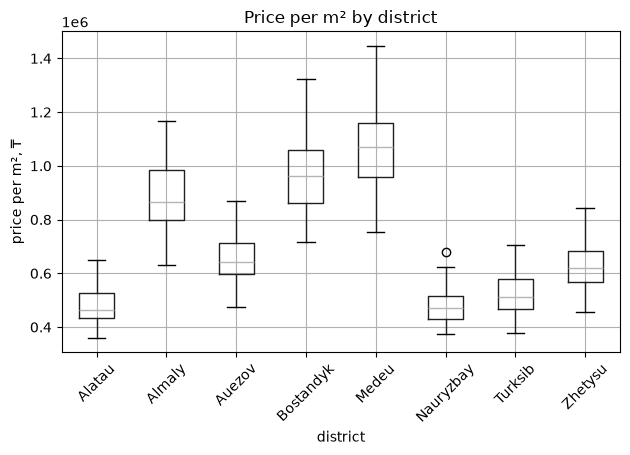

In [24]:
import matplotlib.pyplot as plt

df.boxplot(column="price_per_m2", by="district", rot=45)
plt.ylabel("price per m², ₸")
plt.suptitle("")
plt.title("Price per m² by district")
plt.tight_layout()
plt.show()

In **Medeu**, the median `price_per_m2` is approximately **₸1.06 million**, which is the highest among the districts. In **Alatau** and **Nauryzbay**, the median is around **₸470,000**, which is the lowest.

This means that the median price per square meter in the most expensive district is approximately **2.3 times higher** than in the least expensive districts.


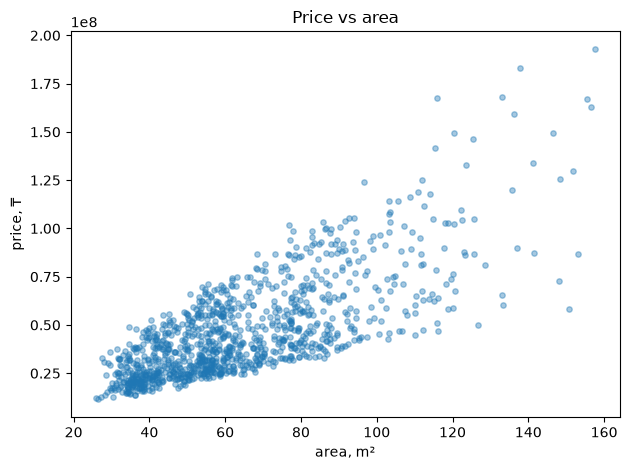

In [25]:
plt.figure()
plt.scatter(df["area_m2"], df["price_kzt"], alpha=0.4, s=15)
plt.xlabel("area, m²")
plt.ylabel("price, ₸")
plt.title("Price vs area")
plt.tight_layout()
plt.show()

There is a **clear positive correlation** between `area_m2` and `price_kzt`: as the apartment area increases from approximately **20 m² to 160 m²**, the price generally increases, reaching around **₸100 million**.

However, above **100 m²**, the **variance increases sharply**. This means that for larger apartments, the price is influenced not only by the area but also by other factors, such as **district** and **building_type**.


<Figure size 640x480 with 0 Axes>

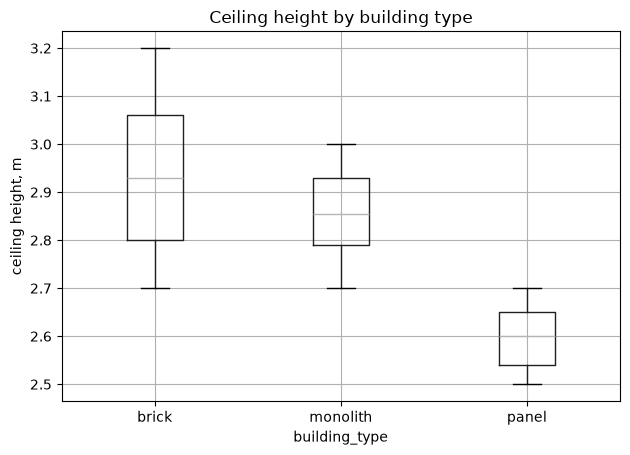

In [26]:
plt.figure()
df.boxplot(column="ceiling_height_m", by="building_type")
plt.ylabel("ceiling height, m")
plt.suptitle("")
plt.title("Ceiling height by building type")
plt.tight_layout()
plt.show()

The median ceiling height is **highest in brick buildings** (approximately **2.93 m**) and **lowest in panel buildings** (approximately **2.60 m**). This represents a difference of about **0.33 m** between brick and panel buildings.

This finding is consistent with the **MAR conclusion from Step 5**, where the missingness rate was also found to depend on `building_type`.


In [27]:
df.to_csv("data/almaty_apartments_clean.csv", index=False)
print("Saved:", df.shape)

Saved: (1080, 13)


## Step 4 & 7 Observations

* **Medeu** district has the highest median `price_per_m2` (approximately **₸1.06M**), while **Alatau** and **Nauryzbay** have the lowest (approximately **₸470K**) — a roughly **2.3× difference** between the highest and lowest districts.

* `area_m2` and `price_kzt` show a **clear positive correlation**. The variance increases sharply above **100 m²**, meaning that the price of larger apartments depends on more than just area, including factors such as `district` and `building_type`.

* The median ceiling height is highest in **brick buildings** (approximately **2.93 m**) and lowest in **panel buildings** (approximately **2.60 m**), with a gap of about **0.33 m**. This is consistent with the **MAR finding from Step 5**, where the missingness rate also depended on `building_type`.

## Cleaning Log

| Step | Operation                                                          | Rows Before | Rows After |      Cells Changed |
| ---- | ------------------------------------------------------------------ | ----------: | ---------: | -----------------: |
| 3a   | Drop exact duplicates                                              |       1,154 |      1,124 |                  — |
| 3a   | Resolve reposts (keep last by date)                                |       1,124 |      1,080 |                  — |
| 3b   | Normalize district spelling                                        |       1,080 |      1,080 | 1,080 (all mapped) |
| 3c   | `rooms`: `"studio"` → 1                                            |       1,080 |      1,080 |                 24 |
| 3c   | `area_m2`: comma decimal fix                                       |       1,080 |      1,080 |                 43 |
| 3c   | `price_kzt`: strip separators/₸                                    |       1,080 |      1,080 |                 84 |
| 4.1  | Sentinels → NaN (`floor=-1`, `year_built=0`, `ceiling_height_m=0`) |       1,080 |      1,080 |                 57 |
| 4.2  | Impossible values (`floor > total_floors`) → NaN                   |       1,080 |      1,080 |                  9 |
| 4.3  | Outliers: `area_m2` ÷ 10 correction (by-district IQR)              |       1,080 |      1,080 |                 10 |
| 5d   | Fill `ceiling_height_m` (median by `building_type`)                |           — |          — |                150 |
| 5d   | Fill `year_built` (global median)                                  |           — |          — |                 76 |
| 5d   | Fill `floor` (global median)                                       |           — |          — |                 21 |

**Clean data saved to:** `data/almaty_apartments_clean.csv` (**1,080 rows**).


In [2]:
!git log --oneline

d7655be Complete notebook: cleaning, missing data, scaling, EDA
f52180c Add cleaned dataset after preprocessing steps 3-5
980564d Initial commit
